# Current project findings: from covariance identification to futures risk

**Question:** what can a covariance model learn from the available observations,
and does the resulting estimate preserve the risks needed for spreads and hedges?

The project has two evidence layers: controlled synthetic experiments, where
truth is known, and an exploratory SHFE copper settlement study, where future
P&L is observed but the true conditional covariance is not. The implemented
estimators use established methods. This overview connects the findings; the
six focused notebooks retain detailed audits and sensitivity analyses.

| Question | Current answer | Evidence boundary |
| --- | --- | --- |
| **RQ1: Identification** | Never-observed covariance pairs can leave spread risk ambiguous, even with unlimited native samples. Smooth curve compression also discards financially important residual changes. | Synthetic identification controls and a separate empirical representation diagnostic. |
| **RQ2: Estimation** | Numerical and sampling errors can be measured separately. Completion needs a stated structural assumption; empirical factor models need residual cross-covariances. | No new operator recovery theorem or universal estimator advantage. |
| **RQ3: Evaluation** | Residual repair improves factor-only risk estimates; direct covariance remains a strong empirical baseline. No transport forecasting advantage is established. | Inspected settlement data, without execution costs or fresh-period confirmation. |

[Full findings](../docs/project-findings.md) ·
[Empirical protocol](../docs/empirical-research-protocol.md) ·
[Synthetic completion report](current_findings.ipynb)

## 1. What has been validated numerically?

The transport calculation distinguishes source covariance $C=LL^\top$ from
normalized innovation covariance

$$V_\Delta=\frac{1}{\Delta}\int_0^\Delta M_s C M_s^\top\,ds.$$

A loading $L$ is nonunique. Finite projected residuals can also contain unresolved
state leakage; a larger matrix alone does not establish infinite-dimensional
recovery. The [fixed-model benchmark](../experiments/results/infinite-transport/report.md)
varies forcing truncation, curve projection and time step separately.

In the [statistical completion study](../docs/statistical-completion-findings.md):

- Under its correctly specified Gaussian canonical control, weighted kernel
  error decreases from **0.07484 at N=128** to **0.02197 at N=2048**
  (replication MCSE 0.01127 and 0.00422; 20 paired replications).
- Equal-native-law controls issue identical fits despite different unseen risks.
  In the separate three-node control, even exact observed covariance permits
  normalized spread variance **[0, 1.68]** across PSD completions.
- Completion supplies an assumption about missing entries. More samples of the
  same fragments do not test that assumption. These are synthetic results,
  not confidence guarantees for market returns.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spde_covariance.empirical_research import load_research_evidence

evidence = load_research_evidence(Path("../experiments/results/shfe-research"))
assert evidence["manifest"]["git_dirty"] is False
print("Verified numerical source:", evidence["manifest"]["git_revision"])
data = evidence["data"]
print(
    f"SHFE copper: {data['sessions']:,} sessions; {data['rows']:,} settlements; "
    f"{data['distinct_contracts']} actual contracts."
)
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10}
)

Verified numerical source: a2f99054886b3154a311665cee7cacd8e6af483c
SHFE copper: 969 sessions; 11,628 settlements; 60 actual contracts.


## 2. A good curve fit can miss the risk of a spread

The empirical study uses 2022 initial history, 2023 validation and **484 subsequent
evaluation origins in 2024–2025**. Holdings use the same actual contracts through
the next settlement, not a rolled continuous series. A copper contract is five
tonnes; portfolio P&L is in CNY. The statistical target is its conditional second
moment, interpreted as variance only under a negligible conditional mean.

For fitted-curve P&L $S$ and reconstruction-residual change $U$, the diagnostic
keeps every term: $\overline{Y^2}=\overline{S^2}+\overline{U^2}+2\overline{SU}$.
The cross term is signed. These are realized sample decompositions, not
independent risk sources or an estimate of the market's latent operator.

The left panel shows why level reconstruction alone is inadequate. The right
panel compares four selected hedge policies on identical future observations.
Each holds one near contract plus two hedge positions bounded by $[-2,2]$.

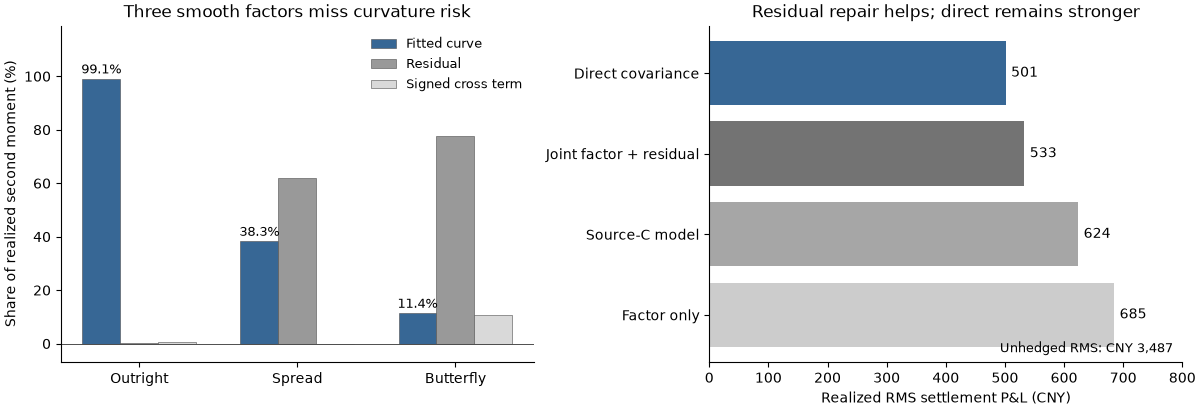

In [2]:
fit = next(
    r for r in evidence["representation"]["fits"] if r["dimension"] == 3 and r["smoothing"] == 1e-6
)
parts = fit["decomposition"]["exposures"]
hedges = {r["method"]: r for r in evidence["joint"]["hedge_summary"]}
policies = ["direct", "joint", "source", "factor"]
labels = {
    "direct": "Direct covariance",
    "joint": "Joint factor + residual",
    "source": "Source-C model",
    "factor": "Factor only",
}
assert all(hedges[m]["common_count"] == 484 for m in policies)
assert all(
    np.isclose(r["modeled_share"] + r["residual_share"] + r["cross_share"], 1) for r in parts
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.1), layout="constrained")
x = np.arange(3)
for j, (key, label, color) in enumerate(
    [
        ("modeled_share", "Fitted curve", "#376795"),
        ("residual_share", "Residual", "0.6"),
        ("cross_share", "Signed cross term", "0.85"),
    ]
):
    axes[0].bar(
        x + (j - 1) * 0.24,
        [100 * r[key] for r in parts],
        0.24,
        label=label,
        color=color,
        edgecolor="0.3",
        linewidth=0.4,
    )
for i, r in enumerate(parts):
    axes[0].text(
        i - 0.24,
        100 * r["modeled_share"] + 2,
        f"{100 * r['modeled_share']:.1f}%",
        ha="center",
        fontsize=9,
    )
axes[0].axhline(0, color="0.3", linewidth=0.7)
axes[0].set(
    xticks=x,
    xticklabels=["Outright", "Spread", "Butterfly"],
    ylabel="Share of realized second moment (%)",
    ylim=(-7, 119),
    title="Three smooth factors miss curvature risk",
)
axes[0].legend(frameon=False, fontsize=9, loc="upper right")

rms = [hedges[m]["realized_rms_cny"] for m in policies]
axes[1].barh(np.arange(4), rms, color=["#376795", "0.45", "0.65", "0.8"])
axes[1].set(
    yticks=np.arange(4),
    yticklabels=[labels[m] for m in policies],
    xlabel="Realized RMS settlement P&L (CNY)",
    xlim=(0, 800),
    title="Residual repair helps; direct remains stronger",
)
axes[1].invert_yaxis()
for i, value in enumerate(rms):
    axes[1].text(value + 9, i, f"{value:,.0f}", va="center")
axes[1].text(
    0.98,
    0.03,
    f"Unhedged RMS: CNY {hedges['unhedged']['realized_rms_cny']:,.0f}",
    transform=axes[1].transAxes,
    ha="right",
    fontsize=9,
)
plt.show()

**Interpretation.** Fitted-curve shares are 99.1% for outright, 38.3% for spread
and 11.4% for butterfly. Four instead of three modes lower median level RMSE
from 48.58 to 44.22 CNY/tonne while median conditioning rises from 70 to 1,611.
The solution is therefore not simply to add factors.

Joint covariance retains factor, residual and cross terms. It substantially
improves factor-only spread/butterfly QLIKE, but gives hedge RMS **CNY 533 versus
501 for direct covariance**. RMS bars are point summaries, not confidence
intervals. The paired comparison below retains uncertainty in squared-P&L units.
Full policy sensitivities remain in [notebook 05](05_joint_residual_risk_and_clocks.ipynb)
and [notebook 06](06_hedging_decisions.ipynb).

In [3]:
print("Paired mean squared hedge P&L minus direct (CNY²)")
print("Rule                       Mean       95% block-bootstrap percentile range")
for method in ("joint", "source", "factor"):
    row = next(
        r
        for r in evidence["joint"]["hedge_paired"]
        if r["method"] == method and r["reference"] == "direct"
    )
    lo, hi = row["bootstrap_percentile_95"]
    print(f"{labels[method]:25s} {row['mean']:9,.0f}     [{lo:,.0f}, {hi:,.0f}]")
    assert row["count"] == 484

Paired mean squared hedge P&L minus direct (CNY²)
Rule                       Mean       95% block-bootstrap percentile range
Joint factor + residual      32,657     [17,545, 47,609]
Source-C model              138,057     [23,501, 298,163]
Factor only                 217,718     [83,309, 398,474]


## 3. Does transport help, and how sensitive is the conclusion?

Matched adjusted-versus-unadjusted factor comparisons establish no forecasting
advantage from transport on this sample. Calendar versus session normalization
also affects exposures differently: joint spread/butterfly QLIKE improves with
session time, while outright worsens. These fixed sensitivities are not a new
test-selected winning rule.

The frozen first-study local SPDE model ranks worse than direct covariance on
spread under primary QLIKE, yet better under secondary quadratic loss. The
table below uses the **same future observations**. Negative differences favor
the local SPDE rule. Quadratic units are scaled explicitly; a different score
weights errors differently and does not justify changing the primary criterion.

In [4]:
for loss, scale, units in [("qlike", 1.0, "QLIKE"), ("quadratic", 1e12, "10¹² CNY⁴")]:
    row = next(
        r
        for r in evidence["scores"]["paired_comparisons"]
        if r["method"] == "spde_local"
        and r["stratum"] == "pooled"
        and r["exposure"] == "spread_3m_6m"
        and r["loss"] == loss
    )
    lo, hi = np.array(row["bootstrap_percentile_95"]) / scale
    print(
        f"Spread, {units}: {row['mean'] / scale:+.3f}; "
        f"95% block-bootstrap percentile range [{lo:+.3f}, {hi:+.3f}]"
    )
    assert row["count"] == 484
print("Historical uncertainty resamples paired session blocks, not independent Monte Carlo paths.")

Spread, QLIKE: +0.953; 95% block-bootstrap percentile range [+0.188, +1.839]
Spread, 10¹² CNY⁴: -0.391; 95% block-bootstrap percentile range [-0.665, -0.177]
Historical uncertainty resamples paired session blocks, not independent Monte Carlo paths.


## 4. Evidence boundaries and how to read the project

The empirical years have informed model development. Past-only issuance prevents
look-ahead within a forecast; it does **not** turn this inspected sample into an
untouched confirmation period. Reported risk reductions mainly reflect correlated
contracts. Fills, bid/ask costs, contract switches, roll execution, margin and
capacity are outside this settlement-risk exercise. No trading alpha, physical
forcing recovery or infinite-dimensional statistical guarantee is established.

| Reader's question | Read next |
| --- | --- |
| What is measured, and how much history exists? | [01 · Data and targets](01_data_and_risk_targets.ipynb) |
| Why can a smooth curve miss spread risk? | [02 · Representation](02_representation_and_identification.ipynb) |
| Is the effect due to transport, window or masking? | [03 · Attribution](03_performance_attribution.ipynb) |
| Do conclusions depend on scoring and large outcomes? | [04 · Forecast scores](04_forecast_scores_and_model_risk.ipynb) |
| What does residual modeling repair? | [05 · Joint risk and clocks](05_joint_residual_risk_and_clocks.ipynb) |
| What happens to bounded hedge decisions? | [06 · Hedging](06_hedging_decisions.ipynb) |
| What was the unchanged initial study? | [Frozen first empirical benchmark](shfe_empirical.ipynb) |
| What do missing observations identify? | [Synthetic completion findings](current_findings.ipynb) |

All empirical figures here read checksummed public aggregates; raw exchange
files, reconstructed daily curves and individual P&Ls stay local. The
[report and manifest](../experiments/results/shfe-research/report.md) retain
configuration, source revision and environment. Reproduce the presentation with
`uv run python scripts/build_project_overview.py --execute`; this does not refit
models or rerun the Monte Carlo studies.

Before another research increment, the project now has a concise statement of
what succeeded, what failed and what remains untested. A revised empirical
policy needs a frozen protocol and an uninspected evaluation period.